# 10 · Capital mobility between sectors, across the EU

Notebook 9 estimated the capital-mobility coefficient `μ` between Portugal's sectors and could not pin it down. With one country, the year effects that absorb the common investment cycle also absorb most of what is left, and the sign changed with the period and with how the self-employed are counted. Its conclusion asked for a panel of sectors in several countries, where **country × year effects absorb each national credit cycle** and the same sector can be compared across countries in the same year. This notebook does that: the 15 market sectors of 26 EU countries, from Eurostat's annual accounts by industry.

The estimating equation is the one of notebook 9, for every country `c`:

`Rᶜᵢₜ / Cᶜᵢ,ₜ₋₁ = μ · (rᶜᵢ,ₜ₋₁ − r̄ᶜₜ₋₁) + effects + error`,

with `Rᶜᵢₜ = (Iᶜᵢₜ − CFCᶜᵢₜ) − σᶜₜ Sᶜᵢₜ` the capital a sector received beyond the share `σᶜₜ = Σᵢ(I − CFC)/Σᵢ S` of its own surplus that its country reinvested, and `r̄ᶜ` the capital-weighted mean profit rate of the country. `Σᵢ Rᶜᵢₜ = 0` in every country and year, like the model's mobility term `μ(rᵢ − r̄)Cᵢ`. `compute_mobility_panel` builds the panel and `estimate_mobility` estimates `μ` with any set of fixed effects (`src/mobility_estimation.jl`).

**The result, in advance: `μ̂` is negative**, about −0.14, precisely estimated, in almost every country and specification. Section 3 shows why that is not a statistical artefact, and section 4 what it says about the model.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, DataFrames, Statistics, LinearAlgebra, Random, Printf
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

In [2]:
"""One line of results: μ̂ and its classical, Driscoll–Kraay and country-clustered standard errors."""
fmt(e) = @sprintf("μ̂ = %6.3f  (se %.3f, Driscoll-Kraay %.3f, clustered by country %.3f)", e.μ, e.se, e.se_DK, e.se_cluster)

"""Value of column `col` in the previous year of the same country and sector (NaN in a country's first year)."""
function lagged(P, col)
    idx = Dict((P.geo[i], P.section[i], P.year[i]) => i for i in 1:nrow(P))
    map(1:nrow(P)) do i
        j = get(idx, (P.geo[i], P.section[i], P.year[i] - 1), 0)
        j == 0 ? NaN : P[j, col]
    end
end

"""
Instrumental-variables estimate of μ: the gap of t−1 instrumented by the gap of t−2, with the same
fixed effects. Returns μ̂, its country-clustered standard error and the first-stage slope.
"""
function mobility_iv(P; effects = (:geo_section, :geo_year))
    z = lagged(P, :gap)
    keep = .!isnan.(z)
    Q, z = P[keep, :], z[keep]
    g = [_effect_labels(Q, e) for e in effects]
    yd, xd, zd = demean_fe(Q.y, g...), demean_fe(Q.gap, g...), demean_fe(z, g...)
    b = dot(zd, yd) / dot(zd, xd)
    u = yd .- b .* xd
    gc, G = _codes(Q.geo)
    h = zeros(G)
    for i in eachindex(u)
        h[gc[i]] += zd[i] * u[i]
    end
    return (μ = b, se_cluster = sqrt(G / (G - 1) * sum(abs2, h)) / abs(dot(zd, xd)),
            first_stage = dot(zd, xd) / dot(zd, zd))
end

"""K-weighted dispersion of the profit rates along a simulated path."""
function dispersion_path(sol, p)
    N = length(p.e)
    map(sol.u) do X
        C, V = X[1:N], X[N+1:2N]
        r = _io_profit_rates(C, V, p.e .* V, p)
        r̄ = sum(r .* C) / sum(C)
        sqrt(sum(C .* (r .- r̄) .^ 2) / sum(C))
    end
end

dispersion_path (generic function with 1 method)

## 1. The panel

`data/eurostat_eu_sectors.csv` (built by `data/build_eurostat_sectors.jl`; provenance in `data/eurostat_eu_sectors_PROVENANCE.md`) has the 19 NACE sections of the EU27 countries except Malta, which publishes no capital stock for mining and energy. As in notebook 9, the baseline leaves out real estate (L, mostly imputed rents on the housing stock) and public administration, education and health (O, P, Q, mostly non-market). Each country contributes the years in which every series is published for every section, so the panel is balanced within a country and unbalanced across countries.

In [3]:
eu = CSV.read(joinpath("..", "..", "data", "eurostat_eu_sectors.csv"), DataFrame)
ALL = sort(String.(unique(eu.section)))
MARKET = setdiff(ALL, ["L", "O", "P", "Q"])
P = compute_mobility_panel(eu; sections = MARKET)
@assert all(abs(sum(g.R)) < 1e-6 * sum(abs, g.R) for g in groupby(P, [:geo, :year]))   # Σᵢ R = 0
coverage = combine(groupby(P, :geo), :year => minimum => :from, :year => maximum => :to, nrow => :rows)
println("$(nrow(P)) observations: $(length(MARKET)) sectors × $(nrow(coverage)) countries")
show(permutedims(coverage[:, [:geo, :from, :to]], :geo); allcols = true, summary = false, eltypes = false)

10665 observations: 15 sectors × 26 countries
 Row │ geo   AT    BE    BG    CY    CZ    DE    DK    EE    EL    ES    FI    FR    HR    HU    IE    IT    LT    LU    LV    NL    PL    PT    RO    SE    SI    SK   
─────┼──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ from  1997  1997  2002  1997  1997  1997  2002  2002  1997  1997  1983  1980  1997  1997  1997  1997  1997  1997  1997  1997  2002  2002  2002  1995  2002  2002
   2 │ to    2025  2024  2022  2023  2025  2024  2025  2023  2023  2024  2025  2025  2023  2023  2024  2023  2023  2023  2023  2024  2023  2023  2023  2023  2024  2024

Most countries enter in 1997 (the capital stock starts in 1995, and the equation needs two lagged years), the ones whose capital stock starts in 2000 enter in 2002, and France, Finland and Sweden go further back.

## 2. The estimate

Four sets of fixed effects, each nested in the next: country × sector effects (each sector's permanent position in its country); plus year effects (the EU-wide cycle); country × year effects instead (each country's own cycle, the fix that notebook 9 asked for); and sector × year effects on top (shocks common to a sector across the EU, such as energy in 2022). The Driscoll–Kraay errors are robust to any correlation within a year and to serial correlation over two years; the clustered errors to any correlation within a country.

In [4]:
specs = [("country × sector", (:geo_section,)),
         ("+ year", (:geo_section, :year)),
         ("+ country × year", (:geo_section, :geo_year)),
         ("+ country × year + sector × year", (:geo_section, :geo_year, :section_year))]
for (lab, eff) in specs
    @printf("%-34s %s\n", lab, fmt(estimate_mobility(P; effects = eff)))
end
base = estimate_mobility(P);

country × sector                   μ̂ = -0.141  (se 0.007, Driscoll-Kraay 0.024, clustered by country 0.048)
+ year                             μ̂ = -0.140  (se 0.007, Driscoll-Kraay 0.024, clustered by country 0.047)


+ country × year                   μ̂ = -0.138  (se 0.007, Driscoll-Kraay 0.022, clustered by country 0.044)
+ country × year + sector × year   μ̂ = -0.141  (se 0.008, Driscoll-Kraay 0.024, clustered by country 0.046)


**`μ̂` ≈ −0.14 in every specification**, with a clustered standard error of 0.05. The national cycles that steered Portugal's estimate barely matter once there are 26 countries: country × year effects move the estimate by 0.002, and sector × year effects by 0.003. In the years a sector's profit rate rose above its country's average, it received *less* capital beyond its own surplus, not more.

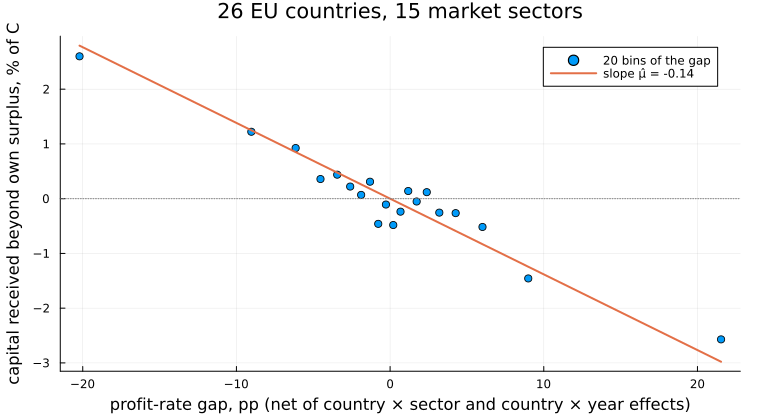

In [5]:
G = [_effect_labels(P, e) for e in (:geo_section, :geo_year)]
xd, yd = demean_fe(P.gap, G...), demean_fe(P.y, G...)
edges = quantile(xd, range(0, 1; length = 21))
bin = [clamp(searchsortedlast(edges, x), 1, 20) for x in xd]
bx = [mean(xd[bin .== k]) for k in 1:20]
by = [mean(yd[bin .== k]) for k in 1:20]
scatter(bx, by, legend = :topright, label = "20 bins of the gap",
        xlabel = "profit-rate gap, pp (net of country × sector and country × year effects)",
        ylabel = "capital received beyond own surplus, % of C",
        title = "26 EU countries, 15 market sectors")
plot!(bx, base.μ .* bx, lw = 2, label = @sprintf("slope μ̂ = %.2f", base.μ))
hline!([0], color = :gray, ls = :dot, label = "")

## 3. Is it built into the measure?

Notebook 9 found the bias that worries most here: the surplus `S` enters the regressor (through `r`) and the dependent variable (through `−σS`) with opposite signs, so measurement error in `S` pulls `μ̂` toward `−σ` (about −0.13 on average here). Three checks:

- **Trimming** the 1% tails of the gap and of the dependent variable, where gross mismeasurement would show.
- **Instrumenting** the gap of `t−1` with the gap of `t−2`. Measurement error that is not persistent from one year to the next does not survive the instrument.
- **The measurement choices** of notebook 9: the self-employed counted at the average wage of their sector, own financing out of last year's surplus, without finance (K), and without Ireland and Luxembourg, where multinationals' profit shifting inflates measured surplus. And the sample: all 19 sections.

In [6]:
lo, hi = quantile(P.gap, [0.01, 0.99]); ylo, yhi = quantile(P.y, [0.01, 0.99])
@printf("%-34s %s\n", "baseline", fmt(base))
@printf("%-34s %s\n", "trimmed 1% tails", fmt(estimate_mobility(P[(lo .<= P.gap .<= hi) .& (ylo .<= P.y .<= yhi), :])))
ivr = mobility_iv(P)
@printf("%-34s μ̂ = %6.3f  (clustered by country %.3f), first stage %.2f\n", "gap instrumented by its lag", ivr.μ, ivr.se_cluster, ivr.first_stage)
for (lab, secs, se_mode, own, drop) in (("self-employed imputed", MARKET, :imputed, :current, String[]),
                                        ("own financing lagged", MARKET, :excluded, :lagged, String[]),
                                        ("without finance (K)", setdiff(MARKET, ["K"]), :excluded, :current, String[]),
                                        ("without IE and LU", MARKET, :excluded, :current, ["IE", "LU"]),
                                        ("all 19 sections", ALL, :excluded, :current, String[]))
    Q = compute_mobility_panel(eu[.!in.(eu.geo, Ref(drop)), :]; sections = secs, self_employed = se_mode, own = own)
    @printf("%-34s %s\n", lab, fmt(estimate_mobility(Q)))
end

baseline                           μ̂ = -0.138  (se 0.007, Driscoll-Kraay 0.022, clustered by country 0.044)
trimmed 1% tails                   μ̂ = -0.086  (se 0.005, Driscoll-Kraay 0.019, clustered by country 0.015)


gap instrumented by its lag        μ̂ = -0.115  (clustered by country 0.035), first stage 0.82
self-employed imputed              μ̂ = -0.066  (se 0.046, Driscoll-Kraay 0.159, clustered by country 0.193)


own financing lagged               μ̂ = -0.167  (se 0.007, Driscoll-Kraay 0.018, clustered by country 0.053)
without finance (K)                μ̂ = -0.149  (se 0.008, Driscoll-Kraay 0.028, clustered by country 0.057)
without IE and LU                  μ̂ = -0.147  (se 0.008, Driscoll-Kraay 0.024, clustered by country 0.048)
all 19 sections                    μ̂ = -0.304  (se 0.007, Driscoll-Kraay 0.031, clustered by country 0.040)


**The sign survives every check.** Trimming shrinks `μ̂` to −0.09 and the instrument gives −0.12 with a strong first stage (0.82), so mismeasured surplus explains a part of the estimate but not its sign. Imputing the self-employed brings it to −0.07 but makes it imprecise (clustered error 0.19), because the imputation leaves some sectors, agriculture above all, with a negative surplus. Lagging own financing, dropping finance or dropping Ireland and Luxembourg changes little, and adding the four non-market sections doubles it to −0.30.

Is the result due to one sector? Leaving out one sector at a time:

In [7]:
drop1 = [(s, estimate_mobility(P[P.section .!= s, :]).μ) for s in MARKET]
println(join([@sprintf("%s %.3f", s, b) for (s, b) in drop1], "   "))

A -0.132   B -0.149   C -0.143   D -0.140   E -0.138   F -0.145   G -0.136   H -0.139   I -0.138   J -0.138   K -0.134   M -0.160   N -0.152   R -0.139   S -0.090


Only other services (S) moves it noticeably, to about −0.09; no sector carries the sign.

## 4. What fails: a common reinvestment share

The dependent variable has two parts, `R/C = (I − CFC)/C − σ S/C`: net investment, and the investment that a common reinvestment share `σ` would have paid for out of the sector's own surplus. Regressing each part on the gap, with the same effects:

In [8]:
flows = select(eu, :geo => ByRow(String) => :geo, :section => ByRow(String) => :section, :year,
               [:GFCF, :CFC] => ((g, c) -> g .- c) => :I, [:GVA, :compensation, :CFC] => ((a, b, c) -> a .- b .- c) => :S)
D = leftjoin(P, flows; on = [:geo, :section, :year])
D.net_investment = 100 .* D.I ./ D.K
D.own_financing = 100 .* D.σ .* D.S ./ D.K
@assert maximum(abs.(D.net_investment .- D.own_financing .- D.y)) < 1e-6 * maximum(abs.(D.y))
parts = map((:net_investment, :own_financing, :y)) do col
    Q = copy(D); Q.y = Q[!, col]
    e = estimate_mobility(Q)
    @printf("%-16s on the gap: %6.3f  (clustered by country %.3f)\n", col, e.μ, e.se_cluster)
    e.μ
end;

net_investment   on the gap:  0.076  (clustered by country 0.013)
own_financing    on the gap:  0.214  (clustered by country 0.039)


y                on the gap: -0.138  (clustered by country 0.044)


**A sector whose profit rate rises one point above its country's average does invest more**: 0.08% of its capital (clustered error 0.01). That is the direction the model expects. But its surplus rises by more than that, and a common reinvestment share would have it invest 0.21% more out of its own surplus alone. Sectors that become more profitable reinvest a *smaller* share of their surplus, and the rest leaves them: distributed as dividends and interest, lent, or invested elsewhere. A negative `μ̂` measures that gap, not capital fleeing profit.

So what the panel rejects is less the sign of `μ` than the model's assumption that every department reinvests the same share `σ_c` of its surplus. With that assumption, all of the response of investment to profitability has to go through `μ`; in the data most of a sector's extra surplus is not reinvested where it was made, and some capital does move toward the sectors whose profit rate rose, more slowly than their surplus grows.

## 5. Country by country

The same equation for each country alone, with sector and year effects (for one country these are its country × sector and country × year effects). Portugal's estimate is notebook 9's.

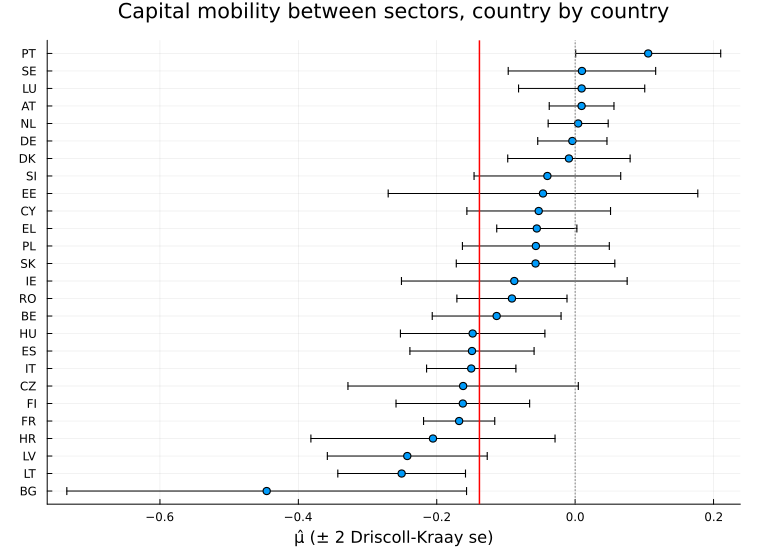

In [9]:
pc = DataFrame(geo = String[], μ = Float64[], se_DK = Float64[])
for g in sort(unique(P.geo))
    e = estimate_mobility(P[P.geo .== g, :])
    push!(pc, (g, e.μ, e.se_DK))
end
sort!(pc, :μ)
@assert pc.μ[pc.geo .== "PT"][1] ≈ estimate_mobility(compute_mobility_panel(eu[eu.geo .== "PT", :]; sections = MARKET);
                                                     effects = (:section, :year)).μ
scatter(pc.μ, 1:nrow(pc), xerror = 2 .* pc.se_DK, yticks = (1:nrow(pc), pc.geo), legend = false,
        xlabel = "μ̂ (± 2 Driscoll-Kraay se)", size = (760, 560),
        title = "Capital mobility between sectors, country by country")
vline!([0], color = :gray, ls = :dot); vline!([base.μ], color = :red, lw = 1.5)

In [10]:
@printf("negative in %d of %d countries; significantly negative (2 se) in %d, significantly positive in %d; median %.3f\n",
        count(<(0), pc.μ), nrow(pc), count(r -> r.μ + 2r.se_DK < 0, eachrow(pc)),
        count(r -> r.μ - 2r.se_DK > 0, eachrow(pc)), median(pc.μ))

negative in 21 of 26 countries; significantly negative (2 se) in 11, significantly positive in 1; median -0.073


**Portugal is the exception, not the rule.** Its 0.11 is the highest of the 26 and the only one whose interval lies above zero, just; Spain, Italy and France are near −0.15, Lithuania, Latvia and Bulgaria lower still, and Germany, the Netherlands, Austria and Sweden near zero. Notebook 9's estimate was not wrong for Portugal; it was not representative.

## 6. Between sectors

In [11]:
btw = estimate_mobility_between(P)
btw_c = estimate_mobility_between(P; within_country = true)
@printf("between country × sectors          μ̂ = %6.3f  (se %.3f, %d units)\n", btw.μ, btw.se, btw.n)
@printf("between sectors of a country       μ̂ = %6.3f  (se %.3f)\n", btw_c.μ, btw_c.se)

between country × sectors          μ̂ = -0.221  (se 0.015, 390 units)
between sectors of a country       μ̂ = -0.225  (se 0.015)


**Between sectors, `μ̂` = −0.22**: as in Portugal (−0.31), the sectors with permanently high measured profit rates receive the least capital beyond their own surplus, which reflects capital intensity and what the accounts count as capital more than disequilibrium (notebook 9, section 2). Country effects change nothing (−0.22).

## 7. Before and after 2008

Did mobility change with the crisis? The question needs care. Splitting the sample and estimating each half with its own effects compares only the movements *within* each period, and gives each sector a different norm before and after; the answer then depends on where the split falls. The cleaner comparison keeps the effects common to the whole period and lets `μ` differ by year: one coefficient on the gap for every year, `μₜ` (`estimate_fe_ols`), from 1997, when every country but the late starters is in the panel.

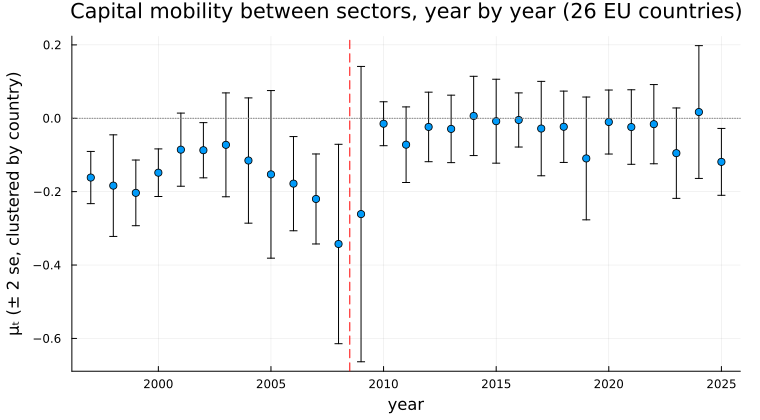

In [12]:
P97 = P[P.year .>= 1997, :]
yrs = sort(unique(P97.year))
fit = estimate_fe_ols(P97, P97.y, reduce(hcat, [P97.gap .* (P97.year .== y) for y in yrs]))
μt, se_t = fit.β, fit.se_cluster
scatter(yrs, μt, yerror = 2 .* se_t, legend = false, xlabel = "year",
        ylabel = "μₜ (± 2 se, clustered by country)",
        title = "Capital mobility between sectors, year by year (26 EU countries)")
hline!([0], color = :gray, ls = :dot); vline!([2008.5], color = :red, ls = :dash)

In [13]:
@printf("mean μₜ 1997-2009: %.3f   2010-2025: %.3f\n", mean(μt[yrs .<= 2009]), mean(μt[yrs .>= 2010]))
println("break after year b: μ before, μ after, t of the change")
for yb in (2002, 2005, 2007, 2008, 2010, 2012, 2015)
    post = Float64.(P97.year .> yb)
    fit = estimate_fe_ols(P97, P97.y, hcat(P97.gap, P97.gap .* post))
    b, se = fit.β, fit.se_cluster
    @printf("  %d   %6.3f  %6.3f   t = %5.2f\n", yb, b[1], b[1] + b[2], b[2] / se[2])
end

mean μₜ 1997-2009: -0.170   2010-2025: -0.035
break after year b: μ before, μ after, t of the change
  2002   -0.153  -0.121   t =  0.74


  2005   -0.144  -0.122   t =  0.47
  2007   -0.151  -0.096   t =  1.21
  2008   -0.160  -0.058   t =  2.32
  2010   -0.153  -0.027   t =  2.17


  2012   -0.149  -0.033   t =  2.22
  2015   -0.145  -0.056   t =  1.92


**`μₜ` was clearly negative up to 2009 and has been close to zero since 2010.** It was most negative in 2008 (−0.34) and 2009 (−0.26). With a break after 2008, `μ̂` goes from −0.16 to −0.06, a change that is significant (t = 2.3); breaks from 2008 to 2012 give a similar change (t ≈ 2.2), later ones a smaller one, and earlier ones none.

So is this a regime switch in `μ`? Section 4's decomposition, before and after 2008, says no:

In [14]:
D97 = D[D.year .>= 1997, :]
post = Float64.(D97.year .> 2008)
for col in (:net_investment, :own_financing, :y)
    fit = estimate_fe_ols(D97, D97[!, col], hcat(D97.gap, D97.gap .* post))
    b, se = fit.β, fit.se_cluster
    @printf("%-16s on the gap: up to 2008 %6.3f, after %6.3f  (t of the change %5.2f)\n", col, b[1], b[1] + b[2], b[2] / se[2])
end
σ_cy = unique(P97[:, [:geo, :year, :σ]])
@printf("reinvestment share σ, mean over countries: up to 2008 %.3f, after %.3f\n",
        mean(σ_cy.σ[σ_cy.year .<= 2008]), mean(σ_cy.σ[σ_cy.year .> 2008]))

net_investment   on the gap: up to 2008  0.075, after  0.090  (t of the change  0.85)
own_financing    on the gap: up to 2008  0.235, after  0.148  (t of the change -2.52)


y                on the gap: up to 2008 -0.160, after -0.058  (t of the change  2.32)
reinvestment share σ, mean over countries: up to 2008 0.185, after 0.101


**The response of investment to profitability did not change**: net investment rises with the gap by 0.075 up to 2008 and 0.090 after, and the difference is not significant. What changed is the reinvestment share net of depreciation: from 0.19 of the surplus on average to 0.10 (notebook 11 shows that the gross share did not change; depreciation rose). The own-financing term `σ S/C` therefore responds less to the gap (0.24 before, 0.15 after), and `μ̂`, the difference of the two, rises toward zero mechanically. The break at 2008 is in reinvestment net of depreciation, not in `μ`: a time-varying `μ` would model the wrong parameter.

## 8. Back in the model

Portugal's 15 market sectors in 2019, as in notebook 9, now including the EU estimate. Nothing in the model prevents a negative `μ`: it then moves capital away from the sectors above the average profit rate, at the rate measured above.

μ = -0.14: EU panel    dispersion at t = 0: 0.0669, t = 20: 0.0132
μ = 0                  dispersion at t = 0: 0.0669, t = 20: 0.0106


μ = 0.3: default       dispersion at t = 0: 0.0669, t = 20: 0.0078


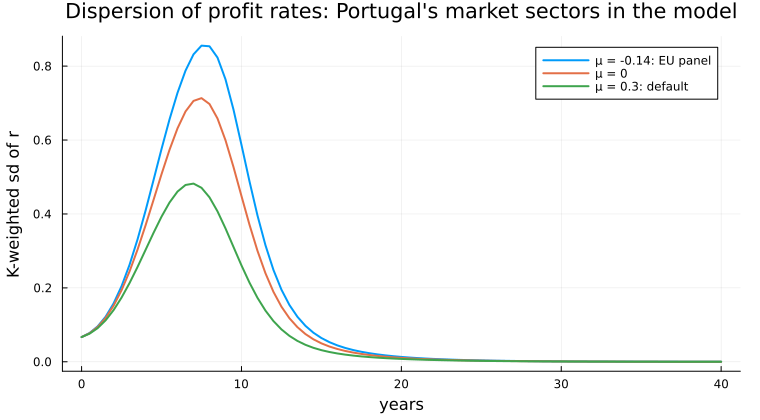

In [15]:
P19 = eu[(eu.geo .== "PT") .& (eu.year .== 2019), :]
σ19 = P.σ[(P.geo .== "PT") .& (P.year .== 2019)][1]
depts = map(MARKET) do s
    row = P19[P19.section .== s, :][1, :]
    S = row.GVA - row.compensation - row.CFC
    Department(String(s); c = row.capital_stock, v = row.compensation, e = max(S / row.compensation, 0.1),
               σ_c = σ19, σ_v = 0.1, δ = row.CFC / row.capital_stock)
end
plt = plot(xlabel = "years", ylabel = "K-weighted sd of r", legend = :topright,
           title = "Dispersion of profit rates: Portugal's market sectors in the model")
μ_eu = round(base.μ, digits = 2)
for (μ, lab) in ((μ_eu, "μ = $μ_eu: EU panel"), (0.0, "μ = 0"), (0.3, "μ = 0.3: default"))
    sol, _, p = simulate_Ndept_custom(deepcopy(depts); T = 40.0, seed = 1, coupled = true, μ = μ)
    d = dispersion_path(sol, p)
    plot!(plt, sol.t, d, lw = 2, label = lab)
    @printf("%-22s dispersion at t = 0: %.4f, t = 20: %.4f\n", lab, d[1], d[findfirst(>=(20.0), sol.t)])
end
plt

With the EU estimate, mobility slows the convergence of profit rates instead of speeding it, from 0.011 at year 20 with `μ` = 0 to 0.013, but the departments' own accumulation still equalizes them. In the model a negative `μ` is a small correction; what the data contradict more strongly is the common `σ_c` of section 4, which the model applies to every department.

## What the EU panel says about `μ` between sectors

- **`μ̂` ≈ −0.14** (clustered error 0.05), with any set of fixed effects, after trimming (−0.09), with the gap instrumented by its lag (−0.12), and negative in 21 of 26 countries. Portugal's positive estimate (notebook 9) is the exception.
- **It is not mainly a measurement artefact**, although mismeasured surplus contributes to it: neither the instrument nor the measurement choices change the sign.
- **What it rejects is the common reinvestment share.** Net investment does rise with the profit-rate gap (0.08), but much less than the sector's surplus: profitable sectors pay out or lend most of what they gain, and a model in which every department reinvests the same `σ_c` has to read that as negative mobility.
- **The break at 2008 is in the net reinvestment share, not in mobility.** `μ̂` rose from −0.16 to −0.06 after 2008, but only because the common share reinvested net of depreciation halved (0.19 to 0.10); the response of net investment to the gap was the same before and after.
- **Between countries it is the other way round**: notebook 8 estimated a positive `μ̂` ≈ 0.22 from current accounts, a measure of the transfer that does not depend on the surplus. Capital crosses borders toward profitability, and within a country it does not obviously flow from sector to sector after it.

Two extensions follow from this. One is a reinvestment share that falls with the profit rate, which would let `μ` be estimated net of it: notebook 11. The other is a measure of the transfer independent of the surplus, as notebook 8 had for countries: the financial accounts by sector.